**Generative AI Use**: For the purposes of the assignments, the use of generative AI is subject to the same policies regarding collaboration. Just as with other collaborators, each student must write down the solutions independently of the output of the interaction and the submission should include a note denoting the nature of the collaboration. The use of generative AI tools to substantially complete sections of the assignments is not in line with the spirit of the assignments, and would be a violation of the [Honor Code](https://communitystandards.stanford.edu/policies-and-guidance/honor-code).

---

**中文对照（参考译文，不含解答）**

**生成式 AI 的使用**：本作业对生成式 AI 的使用采用与协作相同的规则。与其他协作者交流之后，每位学生仍须独立写出自己的解答，不能直接依赖交流中得到的输出；提交时应附上说明，如实记录协作的性质。使用生成式 AI 实质性地完成作业的大部分内容，不符合本作业的教学目的，也会违反[学术诚信准则](https://communitystandards.stanford.edu/policies-and-guidance/honor-code)。

In [9]:
# CS231n local environment setup (exercise code unchanged)
# [中文] CS231n 本地环境设置。
from pathlib import Path
import os
import sys

_candidates = [Path.cwd(), *Path.cwd().parents]
_workspace = next((p for p in _candidates if (p / "requirements-local.txt").is_file()
                   and (p / "assignment2" / "cs231n").is_dir()), None)
if _workspace is None:
    raise RuntimeError("Launch Jupyter from the CS231n workspace root.")
ASSIGNMENT_DIR = _workspace / "assignment2"
os.chdir(ASSIGNMENT_DIR)
if str(ASSIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ASSIGNMENT_DIR))
print("Python:", sys.executable)
print("Working directory:", Path.cwd())


Python: D:\cs231n\.venv\Scripts\python.exe
Working directory: D:\cs231n\assignment2


# Image Captioning with RNNs
In this exercise, you will implement vanilla Recurrent Neural Networks and use them to train a model that can generate novel captions for images.

---

**中文对照（参考译文，不含解答）**

# 带 RNNs 的图像说明
在此练习中, 您将执行 香草经常神经网络, 并使用它们来训练一个模型, 可以生成图像的新字幕。

In [10]:

# Setup cell.
# [中文] 环境与导入设置单元。
import time, os, json
import numpy as np
import torch
import matplotlib.pyplot as plt

from cs231n.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cs231n.rnn_layers_pytorch import *
from cs231n.captioning_solver_pytorch import CaptioningSolverPytorch
from cs231n.classifiers.rnn_pytorch import CaptioningRNN
from cs231n.coco_utils import load_coco_data, sample_coco_minibatch, decode_captions
from cs231n.image_utils import image_from_url

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # Set default size of plots.
# [中文] 设置图像的默认显示大小。
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

import sys
import types
import importlib

if "imp" not in sys.modules:
    imp = types.ModuleType("imp")
    imp.reload = importlib.reload
    sys.modules["imp"] = imp

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """ returns relative error """
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# COCO Dataset
For this exercise, we will use the 2014 release of the [COCO dataset](https://cocodataset.org/), a standard testbed for image captioning. The dataset consists of 80,000 training images and 40,000 validation images, each annotated with 5 captions written by workers on Amazon Mechanical Turk.

**Image features.** We have preprocessed the data and extracted features for you already. For all images, we have extracted features from the fc7 layer of the VGG-16 network pretrained on ImageNet, and these features are stored in the files `train2014_vgg16_fc7.h5` and `val2014_vgg16_fc7.h5`. To cut down on processing time and memory requirements, we have reduced the dimensionality of the features from 4096 to 512 using Principal Component Analysis (PCA), and these features are stored in the files `train2014_vgg16_fc7_pca.h5` and `val2014_vgg16_fc7_pca.h5`. The raw images take up nearly 20GB of space so we have not included them in the download. Since all images are taken from Flickr, we have stored the URLs of the training and validation images in the files `train2014_urls.txt` and `val2014_urls.txt`. This allows you to download images on-the-fly for visualization.

**Captions.** Dealing with strings is inefficient, so we will work with an encoded version of the captions. Each word is assigned an integer ID, allowing us to represent a caption by a sequence of integers. The mapping between integer IDs and words is in the file `coco2014_vocab.json`, and you can use the function `decode_captions` from the file `cs231n/coco_utils.py` to convert NumPy arrays of integer IDs back into strings.

**Tokens.** There are a couple special tokens that we add to the vocabulary, and we have taken care of all implementation details around special tokens for you. We prepend a special `<START>` token and append an `<END>` token to the beginning and end of each caption respectively. Rare words are replaced with a special `<UNK>` token (for "unknown"). In addition, since we want to train with minibatches containing captions of different lengths, we pad short captions with a special `<NULL>` token after the `<END>` token and don't compute loss or gradient for `<NULL>` tokens.

You can load all of the COCO data (captions, features, URLs, and vocabulary) using the `load_coco_data` function from the file `cs231n/coco_utils.py`. Run the following cell to do so:

---

**中文对照（参考译文，不含解答）**

# COCO 数据集
本次演习,我们将利用2014排 定 的 会 议[COCO dataset](https://cocodataset.org/)中,图像字幕的标准测试台。该数据集包括80, 000训练图像和40, 000校验图像, 每个附加注释5亚马逊土耳其机械公司 工人写的文章

** 图像特性。 ** 我们已经为您预处理数据和提取特性。 对于所有图像, 我们已经在图像网络上预选的 VGG- 16 网络的 fc7 层中提取了特性, 这些特性被存储在文件 `train2014_vgg16_fc7.h5` 和 `val2014_vgg16_fc7.h5` 中。 为了缩短处理时间和记忆要求, 我们已经使用主构件分析 (PCA) 将特性的维度从 4096 降低到 512, 这些特性存储在文件`train2014_vgg16_fc7_pca.h5` 和`val2014_vgg16_fc7_pca.h5` 中。 原始图像占用了近20GB的空间, 因此我们没有把它们包含在下载中。 由于所有图像都是从Flickr拍摄的, 我们已将这些图像保存在文件上。 将训练和验证图像的 URL 存储在文件 `train2014_urls.txt` 和 `val2014_urls.txt` 中。 这样您就可以在现场下载图像进行可视化。

** 对字符串的处理效率不高, 因此我们将对描述的编码版本工作。 每个单词都会被指定一个整数 ID, 允许我们用一个整数序列代表一个描述。 整数ID和单词之间的映射在文件 `coco2014_vocab.json` 中, 您可以使用文件 `cs231n/coco_utils.py` 中的函数 `decode_captions` 将整数 的 NumPy 数组转换为字符串。

**我们为词汇添加了几个特殊标记,我们已经为你们安排了所有执行细节。我们预设了一个特殊标记。`<START>`标记并附加`<END>`表示每个描述的开头和结尾。`<UNK>`符号 (对于“ 未知” )。 此外, 由于我们想要用含有不同长度的字幕的小型插头来训练, 我们用一个特殊描述插入短描述。`<NULL>`之后的标记`<END>`标记, 不要计算损失或梯度`<NULL>`标志。

您可以使用 `load_coco_data` 函数从文件 `cs231n/coco_utils.py` 上载全部 COCO 数据 (captions, features, URLs, and vocabulary)。 运行以下单元格来这样做:

In [11]:
# Load COCO data from disk into a dictionary.
# We'll work with dimensionality-reduced features for the remainder of this assignment,
# but you can also experiment with the original features on your own by changing the flag below.
# [中文] 从磁盘读取 COCO 数据并保存为字典。本作业后续默认使用降维后的图像特征；也可修改下面的选项，自行尝试原始特征。
data = load_coco_data(pca_features=True)

# Print out all the keys and values from the data dictionary.
# [中文] 打印数据字典的全部键和值。
for k, v in data.items():
    if type(v) == np.ndarray:
        print(k, type(v), v.shape, v.dtype)
    else:
        print(k, type(v), len(v))

base dir  D:\cs231n\assignment2\cs231n\datasets/coco_captioning
train_captions <class 'numpy.ndarray'> (400135, 17) int32
train_image_idxs <class 'numpy.ndarray'> (400135,) int32
val_captions <class 'numpy.ndarray'> (195954, 17) int32
val_image_idxs <class 'numpy.ndarray'> (195954,) int32
train_features <class 'numpy.ndarray'> (82783, 512) float32
val_features <class 'numpy.ndarray'> (40504, 512) float32
idx_to_word <class 'list'> 1004
word_to_idx <class 'dict'> 1004
train_urls <class 'numpy.ndarray'> (82783,) <U63
val_urls <class 'numpy.ndarray'> (40504,) <U63


## Inspect the Data
It is always a good idea to look at examples from the dataset before working with it.

You can use the `sample_coco_minibatch` function from the file `cs231n/coco_utils.py` to sample minibatches of data from the data structure returned from `load_coco_data`. Run the following to sample a small minibatch of training data and show the images and their captions. Running it multiple times and looking at the results helps you to get a sense of the dataset.

---

**中文对照（参考译文，不含解答）**

## 检查数据
在与数据集合作之前先查看数据集的实例,总是一个好主意。

您可以从文件`cs231n/coco_utils.py` 中使用 `sample_coco_minibatch` 函数从 `load_coco_data` 返回的数据结构中提取数据样本。 运行以下数据来样本小批训练数据并显示图像及其描述。 多次运行并查看结果有助于您获取数据集感知。

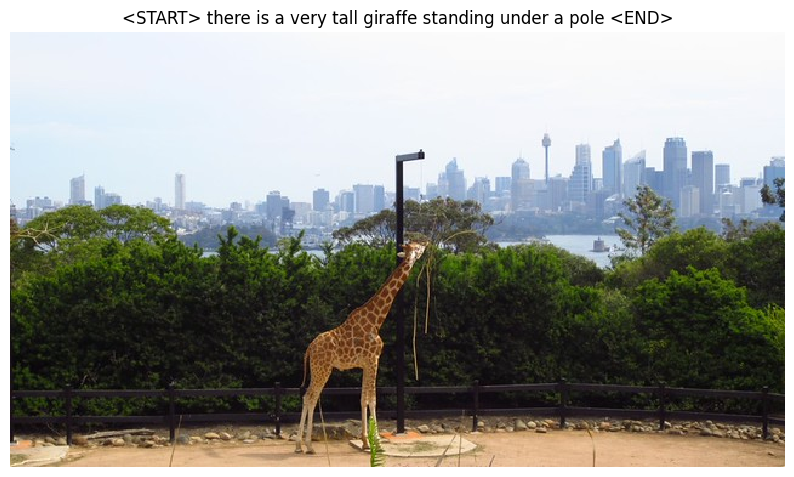

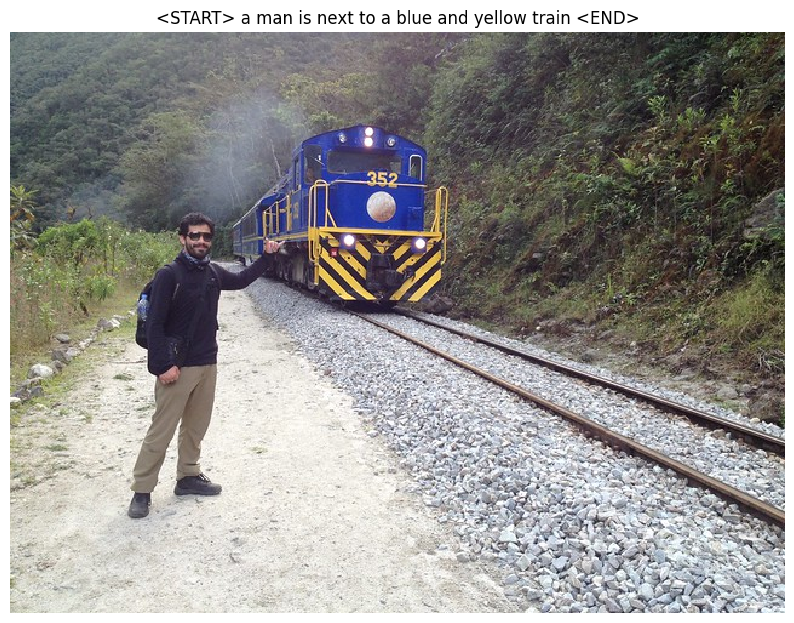

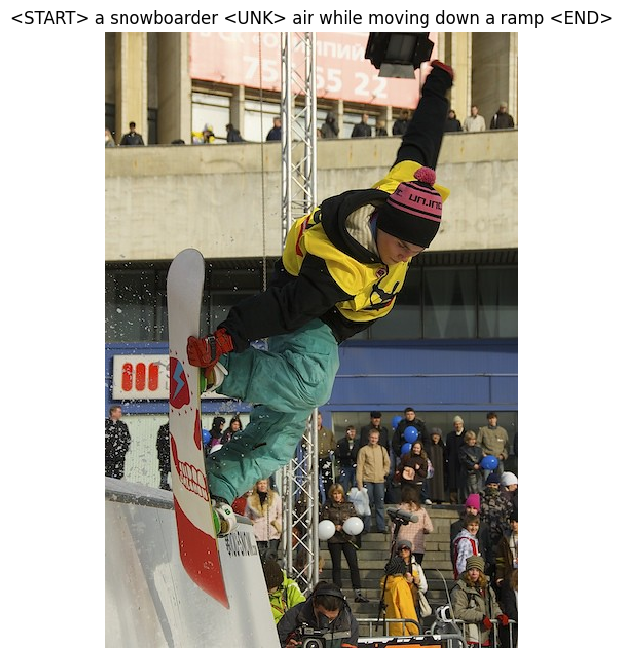

In [12]:
# Sample a minibatch and show the images and captions.
# If you get an error, the URL just no longer exists, so don't worry!
# You can re-sample as many times as you want.
# [中文] 抽取一个小批量，显示图片和对应描述。若图片网址失效导致加载错误，可以重新抽取一批样本。
batch_size = 3

captions, features, urls = sample_coco_minibatch(data, batch_size=batch_size)
for i, (caption, url) in enumerate(zip(captions, urls)):
    plt.imshow(image_from_url(url))
    plt.axis('off')
    caption_str = decode_captions(caption, data['idx_to_word'])
    plt.title(caption_str)
    plt.show()

# Recurrent Neural Network
As discussed in lecture, we will use Recurrent Neural Network (RNN) language models for image captioning. The file `cs231n/rnn_layers_pytorch.py` contains implementations of different layer types that are needed for recurrent neural networks, and the file `cs231n/classifiers/rnn_pytorch.py` uses these layers to implement an image captioning model.

We will first implement different types of RNN layers in `cs231n/rnn_layers_pytorch.py`.

_Optional Reading to get a deeper understanding of RNN : https://www.deeplearningbook.org/contents/rnn.html#pf7_

---

**中文对照（参考译文，不含解答）**

# 经常性神经网络
如讲座中所讨论的,我们将使用经常性神经网络 (RNN) 语言模型进行图像字幕。文件 `cs231n/rnn_layers_pytorch.py` 包含对经常性神经网络所需的不同层类型的实施,文件`cs231n/classifiers/rnn_pytorch.py` 使用这些层来实施图像字幕模型。

我们将首先在 `cs231n/rnn_layers_pytorch.py` 实施不同类型的RNN层。

为加深对 RNN 的理解而选择读取(_O): https://www.deeplearningbook.org/contents/rnn.html#pf7_

# Vanilla RNN: Step Forward
Open the file `cs231n/rnn_layers_pytorch.py`. This file implements the forward passes for different types of layers that are commonly used in recurrent neural networks. Note that since we use pytorch, the backward pass will be handled by pytorch's autograd.

First implement the function `rnn_step_forward` which implements the forward pass for a single timestep of a vanilla recurrent neural network. After doing so run the following to check your implementation. You should see errors on the order of e-8 or less.

---

**中文对照（参考译文，不含解答）**

# 香草 RNN: 前进一步
打开文件 `cs231n/rnn_layers_pytorch.py`。 此文件对常见神经网络中常用的不同类型的层执行前方传票。 请注意, 既然我们使用闪烁器, 则由 Pytorch 自动处理 反向传播。

首先执行一个函数`rnn_step_forward`, 该函数在香草常态神经网络的单个时间步骤中执行 前向传播。 在这样做后运行以下功能来检查您的执行。 您应该看到e - 8 或更少的顺序上的错误。

In [13]:
N, D, H = 3, 10, 4

x = torch.from_numpy(np.linspace(-0.4, 0.7, num=N*D).reshape(N, D))
prev_h = torch.from_numpy(np.linspace(-0.2, 0.5, num=N*H).reshape(N, H))
Wx = torch.from_numpy(np.linspace(-0.1, 0.9, num=D*H).reshape(D, H))
Wh = torch.from_numpy(np.linspace(-0.3, 0.7, num=H*H).reshape(H, H))
b = torch.from_numpy(np.linspace(-0.2, 0.4, num=H))

next_h = rnn_step_forward(x, prev_h, Wx, Wh, b).numpy()
expected_next_h = np.asarray([
  [-0.58172089, -0.50182032, -0.41232771, -0.31410098],
  [ 0.66854692,  0.79562378,  0.87755553,  0.92795967],
  [ 0.97934501,  0.99144213,  0.99646691,  0.99854353]])

print('next_h error: ', rel_error(expected_next_h, next_h))

next_h error:  6.292421426471037e-09


# Vanilla RNN: Step Backward
Since we implemented `rnn_step_forward` with pytorch, we do NOT have to implement `rnn_step_backward`. We can verify pytorch autograd backward
pass using our numerical gradient checker.

However, if you are feeling adventurous, you can try to implement `rnn_step_backward` yourself. It is not required in this assignment though.

---

**中文对照（参考译文，不含解答）**

# 香草 RNN: 退后一步
由于我们用火炬执行`rnn_step_forward`, 我们不必执行`rnn_step_backward`。 我们可以验证火炬自动向后
使用我们的数值梯度检查器通过。

然而,如果您感到冒险,您可以自己尝试执行 `rnn_step_backward`。但本任务中并不要求这样做。

In [14]:
from cs231n.rnn_layers_pytorch import rnn_step_forward

# Create test inputs
# [中文] 创建测试输入。
np.random.seed(231)
N, D, H = 4, 5, 6
x = torch.from_numpy(np.random.randn(N, D))
h = torch.from_numpy(np.random.randn(N, H))
Wx = torch.from_numpy(np.random.randn(D, H))
Wh = torch.from_numpy(np.random.randn(H, H))
b = torch.from_numpy(np.random.randn(H))

# Enable gradient tracking and do rnn forward pass
# [中文] 启用梯度跟踪并执行 RNN 前向传播。
for tensor in [x, h, Wx, Wh, b]:
  tensor.requires_grad_()
next_h = rnn_step_forward(x, h, Wx, Wh, b)

# Simulate random upstream gradients and do a backward pass using pytorch's
# autograd.
# [中文] 构造随机上游梯度，用 PyTorch 自动求导执行反向传播。
dnext_h = torch.from_numpy(np.random.randn(*next_h.shape))
next_h.backward(dnext_h)

# Collect gradient in separate numpy arrays
# [中文] 将各个梯度分别保存为 NumPy 数组。
dx = x.grad.detach().numpy()
dh = h.grad.detach().numpy()
dWx = Wx.grad.detach().numpy()
dWh = Wh.grad.detach().numpy()
db = b.grad.detach().numpy()
dnext_h = dnext_h.detach().numpy()

# Also convert test inputs to numpy arrays
# [中文] 同时将测试输入转换为 NumPy 数组。
x =  x.detach().numpy()
h =  h.detach().numpy()
Wx = Wx.detach().numpy()
Wh = Wh.detach().numpy()
b =  b.detach().numpy()

# Wrap our forward pass to support numpy array input and output. We use
# `torch.no_grad()` to explicitly disable gradient tracking.
# [中文] 将前向传播包装成可接收、返回 NumPy 数组的函数；使用 torch.no_grad() 明确关闭梯度跟踪。
def rnn_step_forward_numpy(x, h, Wx, Wh, b):
  with torch.no_grad():
    return rnn_step_forward(
        torch.from_numpy(x),
        torch.from_numpy(h),
        torch.from_numpy(Wx),
        torch.from_numpy(Wh),
        torch.from_numpy(b),
    ).numpy()

# Compute numerical gradients and compare.
# [中文] 计算数值梯度并进行比较。
fx = lambda x: rnn_step_forward_numpy(x, h, Wx, Wh, b)
fh = lambda h: rnn_step_forward_numpy(x, h, Wx, Wh, b)
fWx = lambda Wx: rnn_step_forward_numpy(x, h, Wx, Wh, b)
fWh = lambda Wh: rnn_step_forward_numpy(x, h, Wx, Wh, b)
fb = lambda b: rnn_step_forward_numpy(x, h, Wx, Wh, b)

dx_num = eval_numerical_gradient_array(fx, x, dnext_h)
dh_num = eval_numerical_gradient_array(fh, h, dnext_h)
dWx_num = eval_numerical_gradient_array(fWx, Wx, dnext_h)
dWh_num = eval_numerical_gradient_array(fWh, Wh, dnext_h)
db_num = eval_numerical_gradient_array(fb, b, dnext_h)

# You should see errors on the order of 1e-9 or less
# [中文] 误差应在 1e-9 或更小量级。
print('dx error: ', rel_error(dx_num, dx))
print('dh error: ', rel_error(dh_num, dh))
print('dWx error: ', rel_error(dWx_num, dWx))
print('dWh error: ', rel_error(dWh_num, dWh))
print('db error: ', rel_error(db_num, db))

dx error:  2.7604568275107355e-10
dh error:  2.583570205609467e-10
dWx error:  6.228158900579986e-10
dWh error:  5.034265173186601e-10
db error:  1.75514782279763e-11


# Vanilla RNN: Forward
Now that you have implemented the forward for a single timestep of a vanilla RNN, you will use it to implement a RNN that processes an entire sequence of data.

In the file `cs231n/rnn_layers_pytorch.py`, implement the function `rnn_forward`. This should be implemented using the `rnn_step_forward` function that you defined above. After doing so run the following to check your implementation. You should see errors on the order of `e-7` or less.

---

**中文对照（参考译文，不含解答）**

# 香草 RNN: 前进
既然你已经用一个香草 RNN 的单时间步向前, 你就会用它来实施一个处理整个数据序列的 RNN。

在文件中`cs231n/rnn_layers_pytorch.py`,执行函数`rnn_forward`. 这项工作应利用以下手段加以实施:`rnn_step_forward`函数。在进行此操作后,运行以下功能来检查您的执行。您应该看到在`e-7`或更少。 或少于。。 \fn微软雅黑Or less. \fs18\b1\bord1\shad1\3cH2F2F3F}。

In [15]:
from cs231n.rnn_layers_pytorch import rnn_forward

N, T, D, H = 2, 3, 4, 5

x = torch.from_numpy(np.linspace(-0.1, 0.3, num=N*T*D).reshape(N, T, D))
h0 = torch.from_numpy(np.linspace(-0.3, 0.1, num=N*H).reshape(N, H))
Wx = torch.from_numpy(np.linspace(-0.2, 0.4, num=D*H).reshape(D, H))
Wh = torch.from_numpy(np.linspace(-0.4, 0.1, num=H*H).reshape(H, H))
b = torch.from_numpy(np.linspace(-0.7, 0.1, num=H))

h = rnn_forward(x, h0, Wx, Wh, b).numpy()
expected_h = np.asarray([
  [
    [-0.42070749, -0.27279261, -0.11074945,  0.05740409,  0.22236251],
    [-0.39525808, -0.22554661, -0.0409454,   0.14649412,  0.32397316],
    [-0.42305111, -0.24223728, -0.04287027,  0.15997045,  0.35014525],
  ],
  [
    [-0.55857474, -0.39065825, -0.19198182,  0.02378408,  0.23735671],
    [-0.27150199, -0.07088804,  0.13562939,  0.33099728,  0.50158768],
    [-0.51014825, -0.30524429, -0.06755202,  0.17806392,  0.40333043]]])
print('h error: ', rel_error(expected_h, h))

h error:  7.728466151011529e-08


# Vanilla RNN: Backward
As before, we can verify pytorch autograd backward pass using our numerical gradient checker. You can also you can try to implement `rnn_step_backward` yourself if you want. It is not required in this assignment though.



---

**中文对照（参考译文，不含解答）**

# 香草 RNN: 向后
和以前一样,我们可以使用我们的数值梯度校验器来验证 pytoch 自动格化 反向传播。也可以尝试执行 `rnn_step_backward`,如果您想要的话。但本任务中不需要它。



In [16]:
from cs231n.rnn_layers_pytorch import rnn_forward

# Create test inputs
# [中文] 创建测试输入。
np.random.seed(231)
N, D, T, H = 2, 3, 10, 5
x = torch.from_numpy(np.random.randn(N, T, D))
h0 = torch.from_numpy(np.random.randn(N, H))
Wx = torch.from_numpy(np.random.randn(D, H))
Wh = torch.from_numpy(np.random.randn(H, H))
b = torch.from_numpy(np.random.randn(H))

# Enable gradient tracking and do forward pass
# [中文] 启用梯度跟踪并执行前向传播。
for tensor in [x, h0, Wx, Wh, b]:
  tensor.requires_grad_()
h = rnn_forward(x, h0, Wx, Wh, b)

# Simulate random upstream gradients and do a backward pass using pytorch's
# autograd.
# [中文] 构造随机上游梯度，用 PyTorch 自动求导执行反向传播。
dh = torch.from_numpy(np.random.randn(*h.shape))
h.backward(dh)

# Collect gradient in separate numpy arrays
# [中文] 将各个梯度分别保存为 NumPy 数组。
dx = x.grad.detach().numpy()
dh0 = h0.grad.detach().numpy()
dWx = Wx.grad.detach().numpy()
dWh = Wh.grad.detach().numpy()
db = b.grad.detach().numpy()
dh = dh.detach().numpy()

# Also convert test inputs to numpy arrays
# [中文] 同时将测试输入转换为 NumPy 数组。
x =  x.detach().numpy()
h0 =  h0.detach().numpy()
Wx = Wx.detach().numpy()
Wh = Wh.detach().numpy()
b =  b.detach().numpy()

# Wrap our forward pass to support numpy array input and output. We use
# `torch.no_grad()` to explicitly disable gradient tracking.
# [中文] 将前向传播包装成可接收、返回 NumPy 数组的函数；使用 torch.no_grad() 明确关闭梯度跟踪。
def rnn_forward_numpy(x, h0, Wx, Wh, b):
  with torch.no_grad():
    return rnn_forward(
        torch.from_numpy(x),
        torch.from_numpy(h0),
        torch.from_numpy(Wx),
        torch.from_numpy(Wh),
        torch.from_numpy(b),
    ).numpy()


fx = lambda x: rnn_forward_numpy(x, h0, Wx, Wh, b)
fh0 = lambda h0: rnn_forward_numpy(x, h0, Wx, Wh, b)
fWx = lambda Wx: rnn_forward_numpy(x, h0, Wx, Wh, b)
fWh = lambda Wh: rnn_forward_numpy(x, h0, Wx, Wh, b)
fb = lambda b: rnn_forward_numpy(x, h0, Wx, Wh, b)

dx_num = eval_numerical_gradient_array(fx, x, dh)
dh0_num = eval_numerical_gradient_array(fh0, h0, dh)
dWx_num = eval_numerical_gradient_array(fWx, Wx, dh)
dWh_num = eval_numerical_gradient_array(fWh, Wh, dh)
db_num = eval_numerical_gradient_array(fb, b, dh)

# You should see errors on the order of 1e-6 or less
# [中文] 误差应在 1e-6 或更小量级。
print('dx error: ', rel_error(dx_num, dx))
print('dh0 error: ', rel_error(dh0_num, dh0))
print('dWx error: ', rel_error(dWx_num, dWx))
print('dWh error: ', rel_error(dWh_num, dWh))
print('db error: ', rel_error(db_num, db))

dx error:  1.5308538969014343e-09
dh0 error:  3.37857687123734e-09
dWx error:  7.330830593233666e-09
dWh error:  1.3108519371833455e-07
db error:  2.734771903614818e-10


# Word Embedding: Forward
In deep learning systems, we commonly represent words using vectors. Each word of the vocabulary will be associated with a vector, and these vectors will be learned jointly with the rest of the system.

In the file `cs231n/rnn_layers_pytorch.py`, implement the function `word_embedding_forward` to convert words (represented by integers) into vectors. Run the following to check your implementation. You should see an error on the order of `e-8` or less.

---

**中文对照（参考译文，不含解答）**

# 嵌入单词: 前进
在深层学习系统中,我们通常代表使用矢量的单词。 词汇中的每个单词都将与矢量相关联, 这些矢量将与系统其他部分共同学习。

在文件 `cs231n/rnn_layers_pytorch.py` 中,执行函数 `word_embedding_forward` 将单词 (represented by integers) 转换为矢量。运行以下操作来检查您的执行。您应该看到在 `e-8` 或更少的顺序上的错误。

In [17]:
N, T, V, D = 2, 4, 5, 3

x = torch.from_numpy(np.asarray([[0, 3, 1, 2], [2, 1, 0, 3]]))
W = torch.from_numpy(np.linspace(0, 1, num=V*D).reshape(V, D))

out = word_embedding_forward(x, W).numpy()
expected_out = np.asarray([
 [[ 0.,          0.07142857,  0.14285714],
  [ 0.64285714,  0.71428571,  0.78571429],
  [ 0.21428571,  0.28571429,  0.35714286],
  [ 0.42857143,  0.5,         0.57142857]],
 [[ 0.42857143,  0.5,         0.57142857],
  [ 0.21428571,  0.28571429,  0.35714286],
  [ 0.,          0.07142857,  0.14285714],
  [ 0.64285714,  0.71428571,  0.78571429]]])

print('out error: ', rel_error(expected_out, out))

out error:  1.0000000094736443e-08


# Word Embedding: Backward
As before, we can verify pytorch autograd backward pass using our numerical gradient checker. You can also you can try to implement `word_embedding_backward` yourself if you want. It is not required in this assignment though.

---

**中文对照（参考译文，不含解答）**

# 单词嵌入: 向后
和以前一样,我们可以使用我们的数值梯度校验器来验证 pytoch 自动格化 反向传播。也可以尝试执行 `word_embedding_backward`,如果您想要的话。但本任务中不需要它。

In [18]:
np.random.seed(231)

N, T, V, D = 50, 3, 5, 6
x = torch.from_numpy(np.random.randint(V, size=(N, T)))
W = torch.from_numpy(np.random.randn(V, D))
W.requires_grad_()

out = word_embedding_forward(x, W)
dout = torch.from_numpy(np.random.randn(*out.shape))
out.backward(dout)

dW = W.grad.detach().numpy()
x = x.detach().numpy()
W = W.detach().numpy()
dout = dout.detach().numpy()

def word_embedding_forward_numpy(x, W):
  return word_embedding_forward(
      torch.from_numpy(x),
      torch.from_numpy(W),
  ).numpy()

f = lambda W: word_embedding_forward_numpy(x, W)
dW_num = eval_numerical_gradient_array(f, W, dout)

# You should see an error on the order of 1e-11 or less
# [中文] 误差应在 1e-11 或更小量级。
print('dW error: ', rel_error(dW, dW_num))

dW error:  3.2774595693100364e-12


# Temporal Affine Layer
At every timestep we use an affine function to transform the RNN hidden vector at that timestep into scores for each word in the vocabulary. Because this is very similar to the affine layer that you implemented in assignment 1, we have provided this function for you in the `temporal_affine_forward`. Run the following to perform numeric gradient checking on the implementation. You should see errors on the order of `e-9` or less.

---

**中文对照（参考译文，不含解答）**

# 时间折叠图层
每次时间步骤中,我们都会使用 apine 函数来将该时间步骤的 RNN 隐藏矢量转换为词汇中每个单词的分数。由于这与您在 1 任务中执行的 phine 层非常相似, 我们在 `temporal_affine_forward` 中为您提供了此函数。 运行以下函数来对执行进行数值梯度检查。 您应该看到 `e-9` 或更少的顺序上的错误。

In [19]:
np.random.seed(231)

# Gradient check for temporal affine layer
# [中文] 对时间序列仿射层做梯度检查。
N, T, D, M = 2, 3, 4, 5
x = torch.from_numpy(np.random.randn(N, T, D))
w = torch.from_numpy(np.random.randn(D, M))
b = torch.from_numpy(np.random.randn(M))

for tensor in [x, w, b]:
  tensor.requires_grad_()
out = temporal_affine_forward(x, w, b)
dout = torch.from_numpy(np.random.randn(*out.shape))
out.backward(dout)

dx = x.grad.detach().numpy()
dw = w.grad.detach().numpy()
db = b.grad.detach().numpy()

x = x.detach().numpy()
w = w.detach().numpy()
b = b.detach().numpy()
dout = dout.detach().numpy()

def temporal_affine_forward_numpy(x, w, b):
  return temporal_affine_forward(
      torch.from_numpy(x),
      torch.from_numpy(w),
      torch.from_numpy(b),
  ).numpy()

fx = lambda x: temporal_affine_forward_numpy(x, w, b)
fw = lambda w: temporal_affine_forward_numpy(x, w, b)
fb = lambda b: temporal_affine_forward_numpy(x, w, b)

dx_num = eval_numerical_gradient_array(fx, x, dout)
dw_num = eval_numerical_gradient_array(fw, w, dout)
db_num = eval_numerical_gradient_array(fb, b, dout)

print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

dx error:  1.8055892397907385e-10
dw error:  1.577204836001982e-10
db error:  5.283486689722725e-12


# Temporal Softmax Loss
In an RNN language model, at every timestep we produce a score for each word in the vocabulary. We know the ground-truth word at each timestep, so we use a softmax loss function to compute loss and gradient at each timestep. We sum the losses over time and average them over the minibatch.

However there is one wrinkle: since we operate over minibatches and different captions may have different lengths, we append `<NULL>` tokens to the end of each caption so they all have the same length. We don't want these `<NULL>` tokens to count toward the loss or gradient, so in addition to scores and ground-truth labels our loss function also accepts a `mask` array that tells it which elements of the scores count towards the loss.

Since this is very similar to the softmax loss function you implemented in assignment 1, we have implemented this loss function for you; look at the `temporal_softmax_loss` function in the file `cs231n/rnn_layers_pytorch.py`.

Run the following cell to sanity check the loss and perform numeric gradient checking on the function. You should see an error for dx on the order of `e-7` or less.

---

**中文对照（参考译文，不含解答）**

# 时空Softmax损失
在 RNN 语言模型中, 每次时间步骤我们都会为词汇中的每个单词出一个分数。 我们知道每个时间步骤的地面真实字, 所以我们使用一个软式损失函数来计算每个时间步骤的损失和梯度。 我们用时间步骤来计算损失, 并在小批中平均计算损失。

然而,有一个皱纹:由于我们操作的是小型的手提箱,不同的描述可能有不同的长度,所以我们附在后面。`<NULL>`每个描述的结尾都有符号, 所以它们都有相同的长度。 我们不希望这些`<NULL>`计算损失或梯度的符号,因此除了计分和地面真实标签外,我们的损失函数也接受`mask`数组中显示损失的计分数要素。

由于此功能与您在任务 1 中执行的软max损失函数非常相似, 我们为您实施了此损失函数; 查看文件 `cs231n/rnn_layers_pytorch.py` 中的 `temporal_softmax_loss` 函数。

运行以下单元格以检查损失是否正常,并在函数上进行数值梯度检查。您应该看到 dx 在 `e-7` 或以下顺序上的错误。

In [20]:
# Sanity check for temporal softmax loss
# [中文] 对时间序列 Softmax 损失进行基本检查。
from cs231n.rnn_layers_pytorch import temporal_softmax_loss

N, T, V = 100, 1, 10

def check_loss(N, T, V, p):
    x = 0.001 * torch.from_numpy(np.random.randn(N, T, V))
    y = torch.from_numpy(np.random.randint(V, size=(N, T)))
    mask = torch.from_numpy(np.random.rand(N, T)) <= p
    print(temporal_softmax_loss(x, y, mask).item())

check_loss(100, 1, 10, 1.0)   # Should be about 2.3
# [中文] 应约为 2.3。
check_loss(100, 10, 10, 1.0)  # Should be about 23
# [中文] 应约为 23。
check_loss(5000, 10, 10, 0.1) # Should be within 2.2-2.4
# [中文] 应在 2.2～2.4 之间。

# Gradient check for temporal softmax loss
# [中文] 对时间序列 Softmax 损失做梯度检查。
np.random.seed(231231)
N, T, V = 7, 8, 9

x = torch.from_numpy(np.random.randn(N, T, V))
y = torch.from_numpy(np.random.randint(V, size=(N, T)))
mask = torch.from_numpy(np.random.rand(N, T) > 0.5)

x.requires_grad_()
loss = temporal_softmax_loss(x, y, mask, verbose=False)
loss.backward()
dx = x.grad.detach().numpy()
x = x.detach().numpy()
dx_num = eval_numerical_gradient(
    lambda x: temporal_softmax_loss(torch.from_numpy(x), y, mask), x, verbose=False)

print('dx error: ', rel_error(dx, dx_num))

2.3027781774290146
23.02598595312723
2.264361179029339
dx error:  5.5228696963589426e-08


# RNN for Image Captioning
Now that you have implemented the necessary layers, you can combine them to build an image captioning model. Open the file `cs231n/classifiers/rnn_pytorch.py` and look at the `CaptioningRNN` class.

Implement the forward pass of the model in the `loss` function. For now you only need to implement the case where `cell_type='rnn'` for vanilla RNNs; you will implement the LSTM case later. After doing so, run the following to check your forward pass using a small test case; you should see error on the order of `e-10` or less.

---

**中文对照（参考译文，不含解答）**

# 用于图像说明的 RNN
既然您已经应用了所需的层, 您可以将其合并来构建图像字幕模型。 打开文件 `cs231n/classifiers/rnn_pytorch.py` 并查看 `CaptioningRNN` 类。

在 `loss` 函数中执行模型的前向传播。 现在您只需要在 Vanilla RNNS 中执行 `cell_type='rnn'` 案例; 您以后会执行 LSTM 案例。 在这样做之后, 运行以下选项, 使用小测试框检查您的 前向传播; 您应该看到在 `e-10` 或更小的顺序上的错误。

In [21]:
N, D, W, H = 10, 20, 30, 40
word_to_idx = {'<NULL>': 0, 'cat': 2, 'dog': 3}
V = len(word_to_idx)
T = 13

model = CaptioningRNN(
    word_to_idx,
    input_dim=D,
    wordvec_dim=W,
    hidden_dim=H,
    cell_type='rnn',
    dtype=torch.float64
)

# Set all model parameters to fixed values
# [中文] 将全部模型参数设置为固定值。
for k, v in model.params.items():
    model.params[k] = torch.from_numpy(
        np.linspace(-1.4, 1.3, num=v.numel()).reshape(*v.shape))

features = torch.from_numpy(np.linspace(-1.5, 0.3, num=(N * D)).reshape(N, D))
captions = torch.from_numpy((np.arange(N * T) % V).reshape(N, T))

loss = model.loss(features, captions).item()
expected_loss = 9.83235591003

print('loss: ', loss)
print('expected loss: ', expected_loss)
print('difference: ', abs(loss - expected_loss))

loss:  9.832355910027388
expected loss:  9.83235591003
difference:  2.611244553918368e-12


Run the following cell to perform numeric gradient checking on the `CaptioningRNN` class; you should see errors around the order of `e-6` or less.

---

**中文对照（参考译文，不含解答）**

运行以下单元格以进行数值梯度检查`CaptioningRNN`类; 您应该看到围绕`e-6`或更少。 或少于。。 \fn微软雅黑Or less. \fs18\b1\bord1\shad1\3cH2F2F3F}。

In [22]:
np.random.seed(231)
torch.manual_seed(231)

batch_size = 2
timesteps = 3
input_dim = 4
wordvec_dim = 5
hidden_dim = 6
word_to_idx = {'<NULL>': 0, 'cat': 2, 'dog': 3}
vocab_size = len(word_to_idx)

captions = torch.from_numpy(np.random.randint(vocab_size, size=(batch_size, timesteps)))
features = torch.from_numpy(np.random.randn(batch_size, input_dim))

model = CaptioningRNN(
    word_to_idx,
    input_dim=input_dim,
    wordvec_dim=wordvec_dim,
    hidden_dim=hidden_dim,
    cell_type='rnn',
    dtype=torch.float64,
)

for k, v in model.params.items():
  v.requires_grad_()
loss = model.loss(features, captions)
loss.backward()
grads = {k: v.grad.detach().numpy() for k, v in model.params.items()}
for k, v in model.params.items():
  v.requires_grad_(False)

for param_name in sorted(grads.keys()):
    def fn(val):
      model.params[param_name] = torch.from_numpy(val)
      ret = model.loss(features, captions).numpy()
      return ret

    param_grad_num = eval_numerical_gradient(
        fn, model.params[param_name].numpy(), verbose=False, h=1e-6)

    e = rel_error(param_grad_num, grads[param_name])
    print('%s relative error: %e' % (param_name, e))

W_embed relative error: 2.367749e-09
W_proj relative error: 2.978530e-08
W_vocab relative error: 3.699956e-09
Wh relative error: 3.542192e-09
Wx relative error: 2.891388e-06
b relative error: 2.259962e-10
b_proj relative error: 7.720399e-10
b_vocab relative error: 4.089136e-09


# Overfit RNN Captioning Model on Small Data
Similar to the `Solver` class that we used to train image classification models on the previous assignment, on this assignment we use a `CaptioningSolverPytorch` class to train image captioning models. Open the file `cs231n/captioning_solver_pytorch.py` and read through the `CaptioningSolverPytorch` class; it should look very familiar.

Once you have familiarized yourself with the API, run the following to make sure your model overfits a small sample of 100 training examples. You should see a final loss of less than 0.1.

---

**中文对照（参考译文，不含解答）**

# 超配小数据 RNN 说明模型
类似于我们用来在上一个任务上训练图像分类模型的 `Solver` 类, 在此任务上我们使用 `CaptioningSolverPytorch` 类来训练图像字幕模型。 打开文件 `cs231n/captioning_solver_pytorch.py` 并通过 `CaptioningSolverPytorch` 类阅读; 它应该看起来很熟悉。

一旦您熟悉了 API, 请运行以下选项, 以确保您的模型比 100 训练示例的样本更合适。 您应该看到最后损失低于 0.1 的样本。

base dir  D:\cs231n\assignment2\cs231n\datasets/coco_captioning
(Iteration 1 / 100) loss: 80.027161
(Iteration 11 / 100) loss: 25.581350
(Iteration 21 / 100) loss: 3.890298
(Iteration 31 / 100) loss: 0.641088
(Iteration 41 / 100) loss: 0.133341
(Iteration 51 / 100) loss: 0.057613
(Iteration 61 / 100) loss: 0.028635
(Iteration 71 / 100) loss: 0.022359
(Iteration 81 / 100) loss: 0.018516
(Iteration 91 / 100) loss: 0.016731


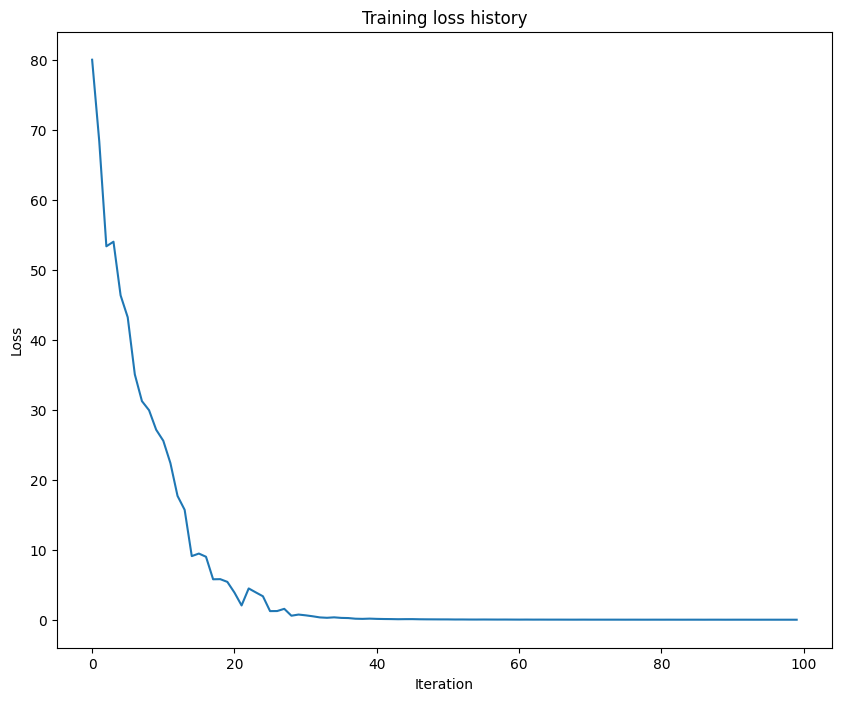

In [23]:
np.random.seed(231)
torch.manual_seed(231)

small_data = load_coco_data(max_train=50)

small_rnn_model = CaptioningRNN(
    cell_type='rnn',
    word_to_idx=data['word_to_idx'],
    input_dim=data['train_features'].shape[1],
    hidden_dim=512,
    wordvec_dim=256,
)

small_rnn_solver = CaptioningSolverPytorch(
    small_rnn_model, small_data,
    num_epochs=50,
    batch_size=25,
    learning_rate=5e-3,
    verbose=True, print_every=10,
)

small_rnn_solver.train()

# Plot the training losses.
# [中文] 绘制训练损失曲线。
plt.plot(small_rnn_solver.loss_history)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Training loss history')
plt.show()

Print final training loss. You should see a final loss of less than 0.1.

---

**中文对照（参考译文，不含解答）**

打印最后训练损失。 您应该看到最后损失小于 0.1。

In [24]:
print('Final loss: ', small_rnn_solver.loss_history[-1])

Final loss:  0.013373599


# RNN Sampling at Test Time
Unlike classification models, image captioning models behave very differently at training time vs. at test time. At training time, we have access to the ground-truth caption, so we feed ground-truth words as input to the RNN at each timestep. At test time, we sample from the distribution over the vocabulary at each timestep and feed the sample as input to the RNN at the next timestep.

In the file `cs231n/classifiers/rnn_pytorch.py`, implement the `sample` method for test-time sampling. After doing so, run the following to sample from your overfitted model on both training and validation data. The samples on training data should be very good. The samples on validation data, however, probably won't make sense.

---

**中文对照（参考译文，不含解答）**

# RNN 测试时取样
与分类模型不同, 图像字幕模型在训练时间对测试时间的表现非常不同。 在训练时间, 我们可以访问地面真相描述, 所以我们在每次时间步骤中将地面真相单词作为输入到 RNN。 在测试时间, 我们从每个时间步骤的词汇分布中取样, 然后在下一个时间步骤里将样本作为输入到RNN 中。

在文件 `cs231n/classifiers/rnn_pytorch.py` 中, 执行测试时间取样的 `sample` 方法。 在这样做之后, 运行以下的样本, 从您过配的模型中提取训练和验证数据。 训练数据的样本应该很好。 但是, 验证数据的样本可能不合理。

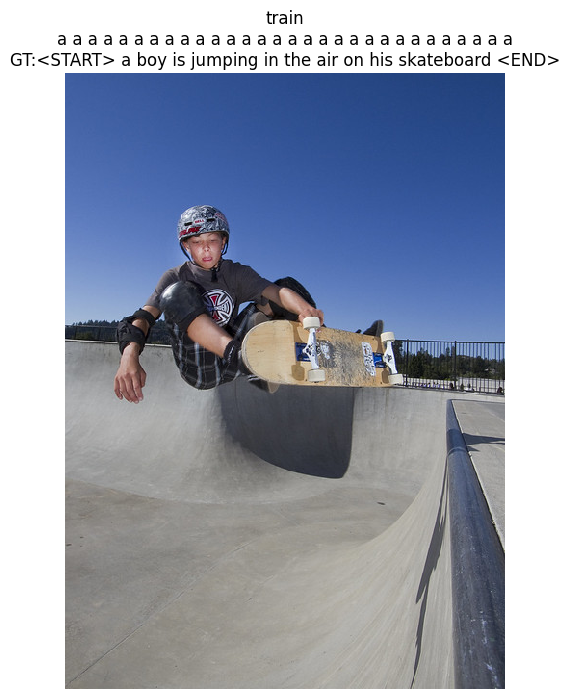

URL Error:  Not Found http://farm6.staticflickr.com/5242/5374783539_ac300e0e08_z.jpg


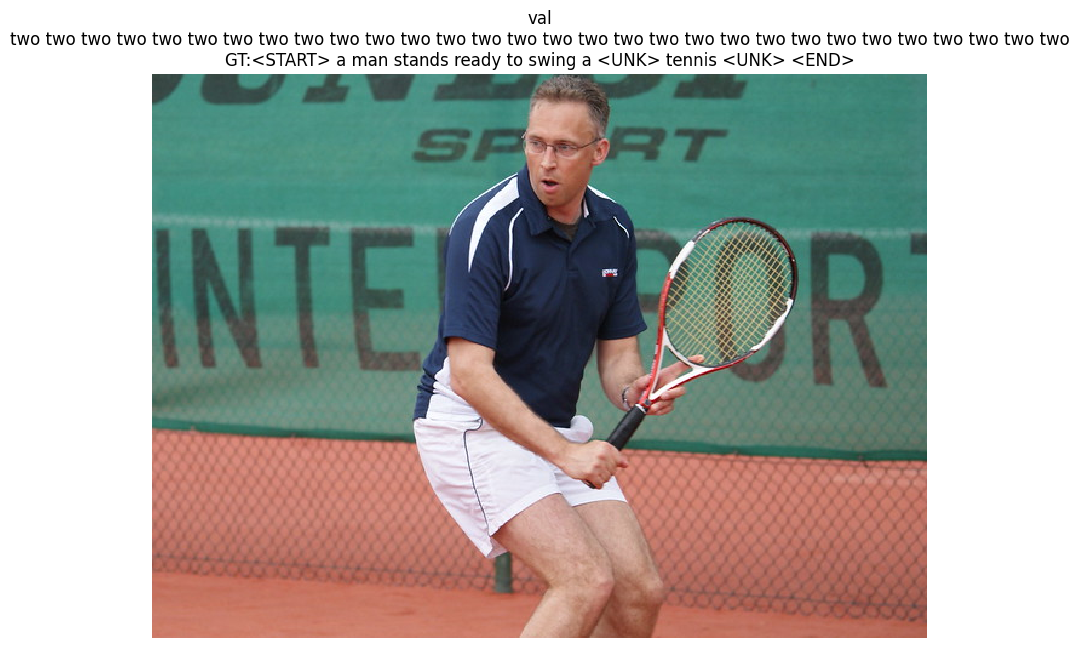

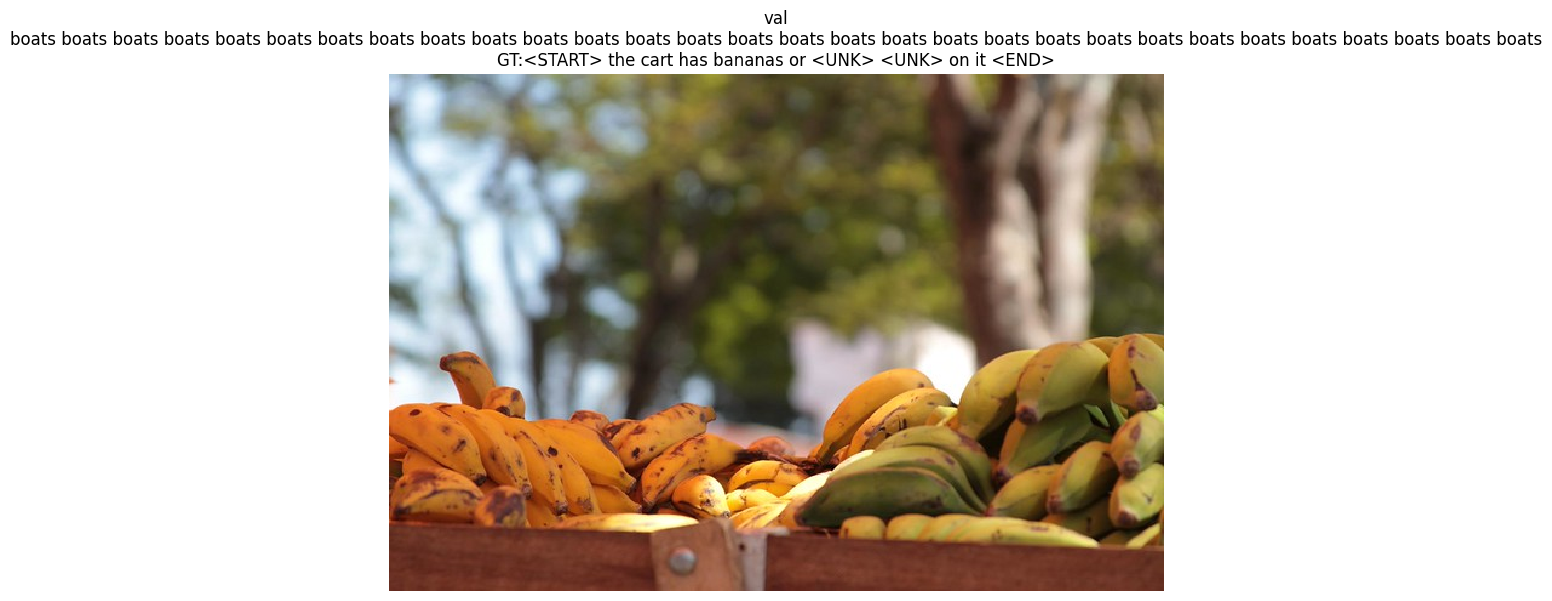

In [29]:
# If you get an error, the URL just no longer exists, so don't worry!
# You can re-sample as many times as you want.
# [中文] 若图片加载失败，可能是原图片网址已失效；可以重新抽取样本。
for split in ['train', 'val']:
    minibatch = sample_coco_minibatch(small_data, split=split, batch_size=2)
    gt_captions, features, urls = minibatch
    gt_captions = decode_captions(gt_captions, data['idx_to_word'])

    sample_captions = small_rnn_model.sample(torch.from_numpy(features)).numpy()
    sample_captions = decode_captions(sample_captions, data['idx_to_word'])

    for gt_caption, sample_caption, url in zip(gt_captions, sample_captions, urls):
        img = image_from_url(url)
        # Skip missing URLs.
        # [中文] 跳过缺失或失效的图片网址。
        if img is None: continue
        plt.imshow(img)
        plt.title('%s\n%s\nGT:%s' % (split, sample_caption, gt_caption))
        plt.axis('off')
        plt.show()

# Inline Question 1

In our current image captioning setup, our RNN language model produces a word at every timestep as its output. However, an alternate way to pose the problem is to train the network to operate over _characters_ (e.g. 'a', 'b', etc.) as opposed to words, so that at it every timestep, it receives the previous character as input and tries to predict the next character in the sequence. For example, the network might generate a caption like

'A', ' ', 'c', 'a', 't', ' ', 'o', 'n', ' ', 'a', ' ', 'b', 'e', 'd'

Can you describe one advantage of an image-captioning model that uses a character-level RNN? Can you also describe one disadvantage? HINT: there are several valid answers, but it might be useful to compare the parameter space of word-level and character-level models.

**Your Answer:**



---

**中文对照（参考译文，不含解答）**

# 随堂问题 1

在当前的图像描述生成任务中，RNN 语言模型在每个时间步输出一个单词。另一种做法是让网络以字符（例如 'a'、'b' 等）为单位：每个时间步接收上一个字符作为输入，并预测序列中的下一个字符。例如，网络可能生成：

'A', ' ', 'c', 'a', 't', ' ', 'o', 'n', ' ', 'a', ' ', 'b', 'e', 'd'

请各描述一个采用字符级 RNN 生成图像描述的优点和缺点。

原题提示：合理答案不止一个；可以比较单词级模型与字符级模型的参数空间。

**你的回答：** 字符种类较少，即字符级模型词表更少，所需要的参数也可能更少，并且可能能拼出新词或生僻词，用词更灵活；而单词种类繁多，因此需要的参数更多。但是字符级模型需要更多时间步来生成单词，生成整句话的时间步就更多了，这使得训练和生成可能更慢。